# PNEUMYST AI · Exploratory Data Analysis

Run with the `.venv` kernel. Charts are also saved to `docs/figures/eda/`.

Section 10 shows real X-rays: clear outputs before committing.
`jupyter nbconvert --clear-output --inplace notebooks/eda.ipynb`

In [ ]:
import json, sys
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))

from dotenv import load_dotenv
load_dotenv(REPO / ".env")

%matplotlib inline
import pandas as pd
from IPython.display import display

import ml.eda.run_eda as eda
from ml.config import data_root

eda.SHOW = True
ROOT = data_root()
OUT = REPO / "docs" / "figures" / "eda"
LOCAL = ROOT / "processed" / "eda"
OUT.mkdir(parents=True, exist_ok=True)
LOCAL.mkdir(parents=True, exist_ok=True)

dfs = eda.load_manifests(ROOT / "processed" / "manifests")
nih = dfs["nih"]
nih_train = nih[nih["split"] == "train"]
{name: len(df) for name, df in dfs.items()}

{'tbx11k': 8248, 'shenzhen': 662, 'montgomery': 138, 'nih': 112093}

## 1. Images per dataset and split

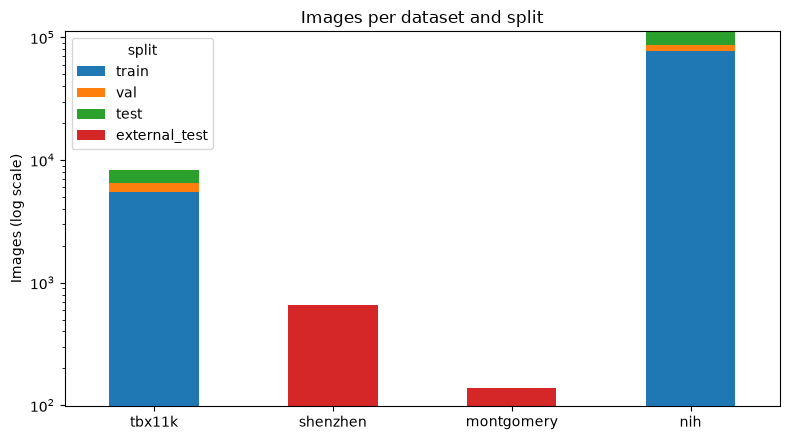

,tbx11k,shenzhen,montgomery,nih
train,5479,0,0,77335
val,977,0,0,9170
test,1792,0,0,25588
external_test,0,662,138,0


In [ ]:
pd.DataFrame(eda.plot_split_sizes(dfs, OUT)).fillna(0).astype(int)

## 2. Tuberculosis label balance

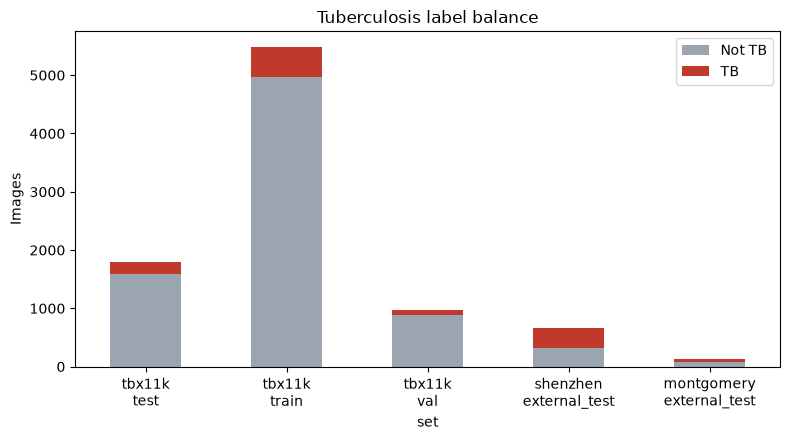

,TB,Not TB
tbx11k/test,200,1592
tbx11k/train,510,4969
tbx11k/val,90,887
shenzhen/external_test,336,326
montgomery/external_test,58,80


In [ ]:
pd.DataFrame(eda.plot_tb_balance(dfs, OUT)).T

## 3. NIH prevalence by split

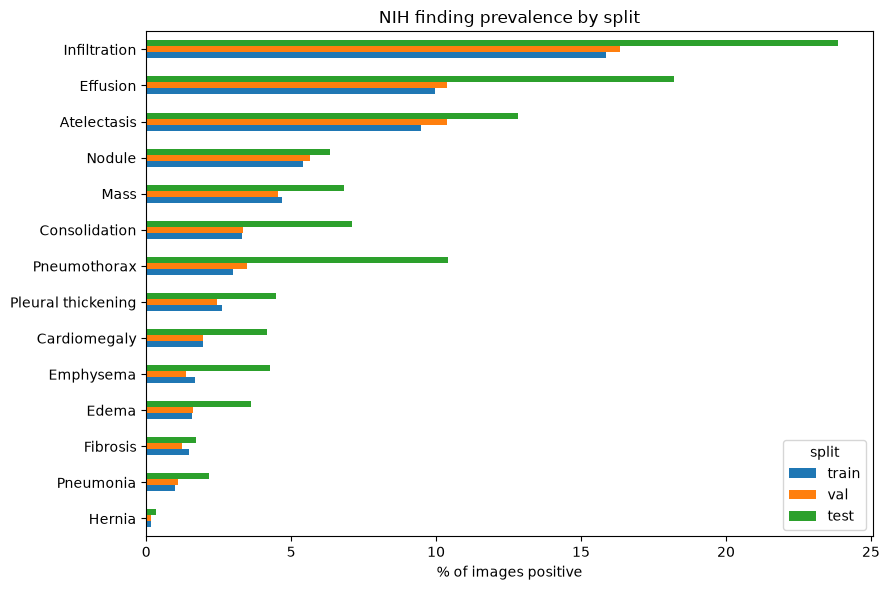

,train,val,test,test_to_train
Pneumothorax,2.99,3.49,10.41,3.48
Emphysema,1.68,1.38,4.27,2.55
Edema,1.59,1.61,3.61,2.27
Pneumonia,1.00,1.11,2.17,2.17
Consolidation,3.29,3.35,7.09,2.16
Cardiomegaly,1.98,1.95,4.18,2.11
Hernia,0.16,0.16,0.34,2.06
Effusion,9.97,10.37,18.20,1.83
Pleural thickening,2.61,2.44,4.47,1.71
Infiltration,15.88,16.35,23.88,1.50


In [ ]:
prev = eda.plot_nih_prevalence(nih, OUT)
(pd.DataFrame(prev["percent"])
   .assign(test_to_train=pd.Series(prev["test_to_train_ratio"]))
   .sort_values("test_to_train", ascending=False))

## 4. Which findings occur together

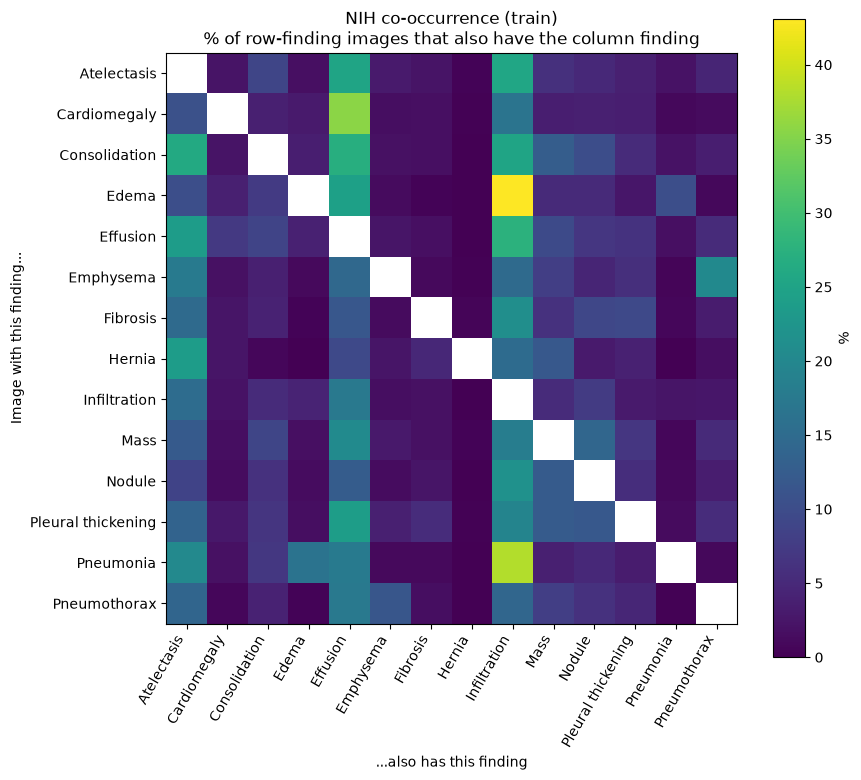

,finding,also,percent
0,Edema,Infiltration,43.1
1,Pneumonia,Infiltration,38.1
2,Cardiomegaly,Effusion,35.7
3,Effusion,Infiltration,27.7
4,Consolidation,Effusion,27.0
5,Consolidation,Atelectasis,26.1
6,Atelectasis,Infiltration,25.6
7,Consolidation,Infiltration,25.2
8,Atelectasis,Effusion,25.1
9,Edema,Effusion,24.6


In [ ]:
pd.DataFrame(eda.plot_nih_cooccurrence(nih_train, OUT))

## 5. Findings per image

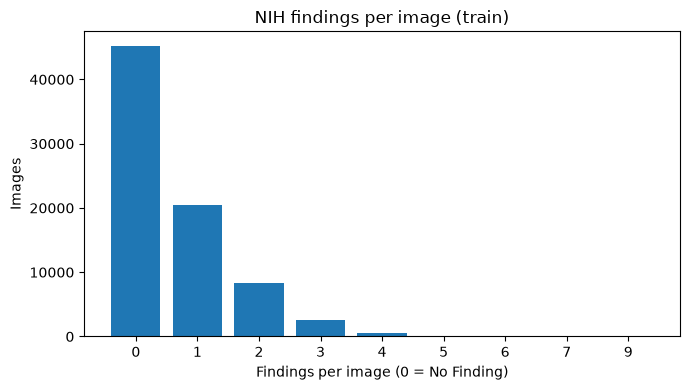

,images
0,45220
1,20476
2,8292
3,2584
4,593
5,128
6,33
7,7
9,2


In [ ]:
pd.Series(eda.plot_labels_per_image(nih_train, OUT), name="images").to_frame()

## 6. AP-view shortcut check

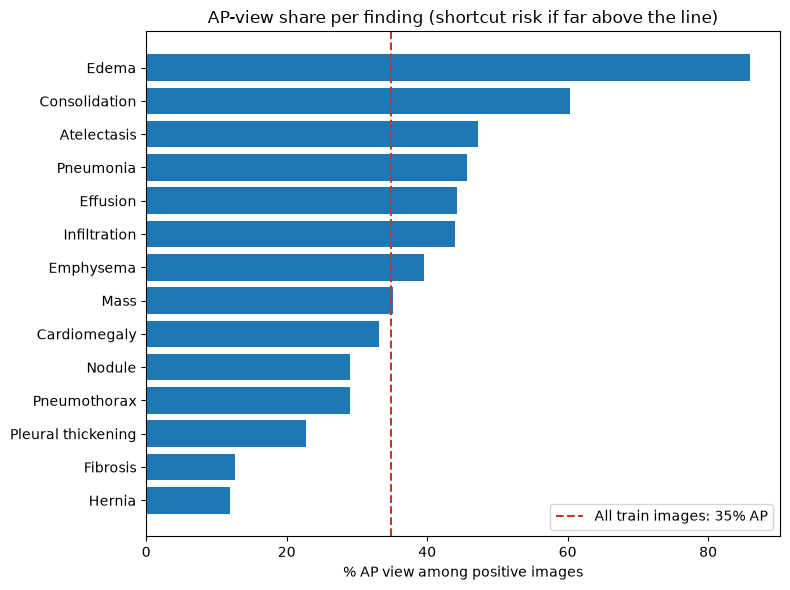

,% AP,vs_overall
Edema,85.9,51.0
Consolidation,60.4,25.5
Atelectasis,47.3,12.4
Pneumonia,45.6,10.7
Effusion,44.3,9.4
Infiltration,43.9,9.0
Emphysema,39.5,4.6
Mass,35.1,0.2
Cardiomegaly,33.1,-1.8
Nodule,29.0,-5.9


In [ ]:
view = eda.plot_view_shortcut(nih_train, OUT)
(pd.Series(view["ap_percent_among_positives"], name="% AP")
   .sort_values(ascending=False).to_frame()
   .assign(vs_overall=lambda d: (d["% AP"] - view["overall_ap_percent"]).round(1)))

## 7. Demographics

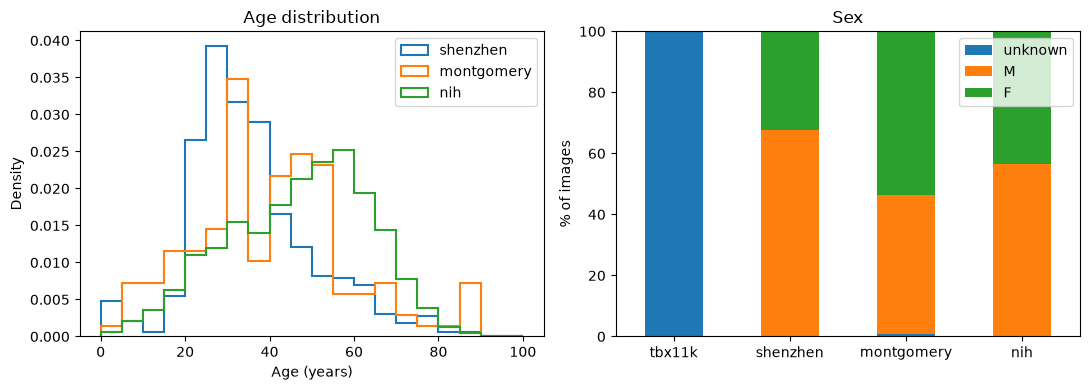

,age_median,age_known,sex
tbx11k,None,0,{'unknown': 8248}
shenzhen,33.0,662,"{'M': 449, 'F': 213}"
montgomery,40.0,138,"{'F': 74, 'M': 63, 'unknown': 1}"
nih,49.0,112093,"{'M': 63329, 'F': 48764}"


In [ ]:
pd.DataFrame(eda.plot_demographics(dfs, OUT)).T

## 8. NIH images per patient

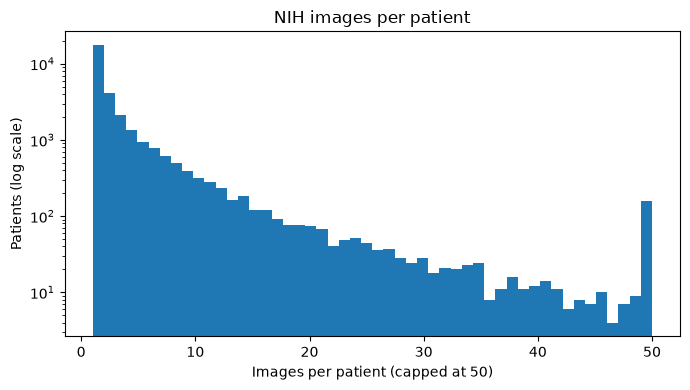

{'patients': 30805, 'median': 1.0, 'max': 184, 'patients_with_10plus': 2545}


,images,patients,images_per_patient
split,,,
test,25588,2797,9.1
train,77335,25207,3.1
val,9170,2801,3.3


In [ ]:
print(eda.plot_followups(nih, OUT))
(nih.groupby("split")
    .agg(images=("image_id", "size"), patients=("patient_id", "nunique"))
    .assign(images_per_patient=lambda d: (d.images / d.patients).round(1)))

## 9. Image properties (sampled)

Raise `N` for a bigger sample (slower).

sample nih: 100%|██████████| 300/300 [00:03<00:00, 86.04it/s]


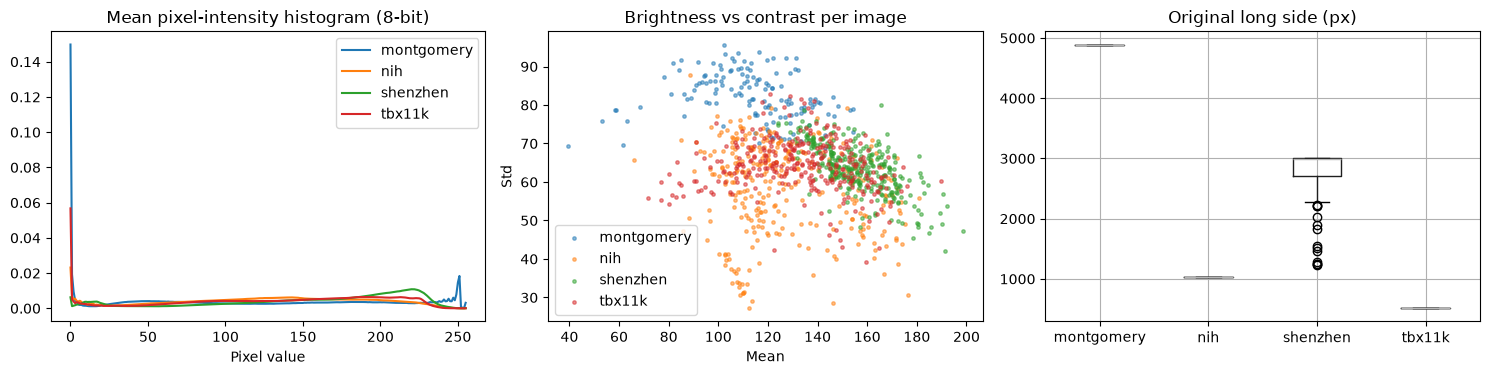

,n,modes,width_range,height_range,mean_intensity,std_intensity
montgomery,138,{'L': 138},"[4020, 4892]","[4020, 4892]",112.9,82.4
nih,300,"{'L': 299, 'RGBA': 1}","[1024, 1024]","[1024, 1024]",125.7,58.1
shenzhen,300,"{'P': 288, 'RGB': 12}","[1225, 3001]","[989, 3001]",156.1,63.4
tbx11k,300,{'RGB': 300},"[512, 512]","[512, 512]",132.6,64.2


In [ ]:
N = 300
stats = eda.sample_image_stats(dfs, ROOT, N, seed=42)
pd.DataFrame(eda.plot_image_stats(stats, OUT)).T

## 10. Sample X-rays (local only)

Check for borders, inverted images and burned-in text.

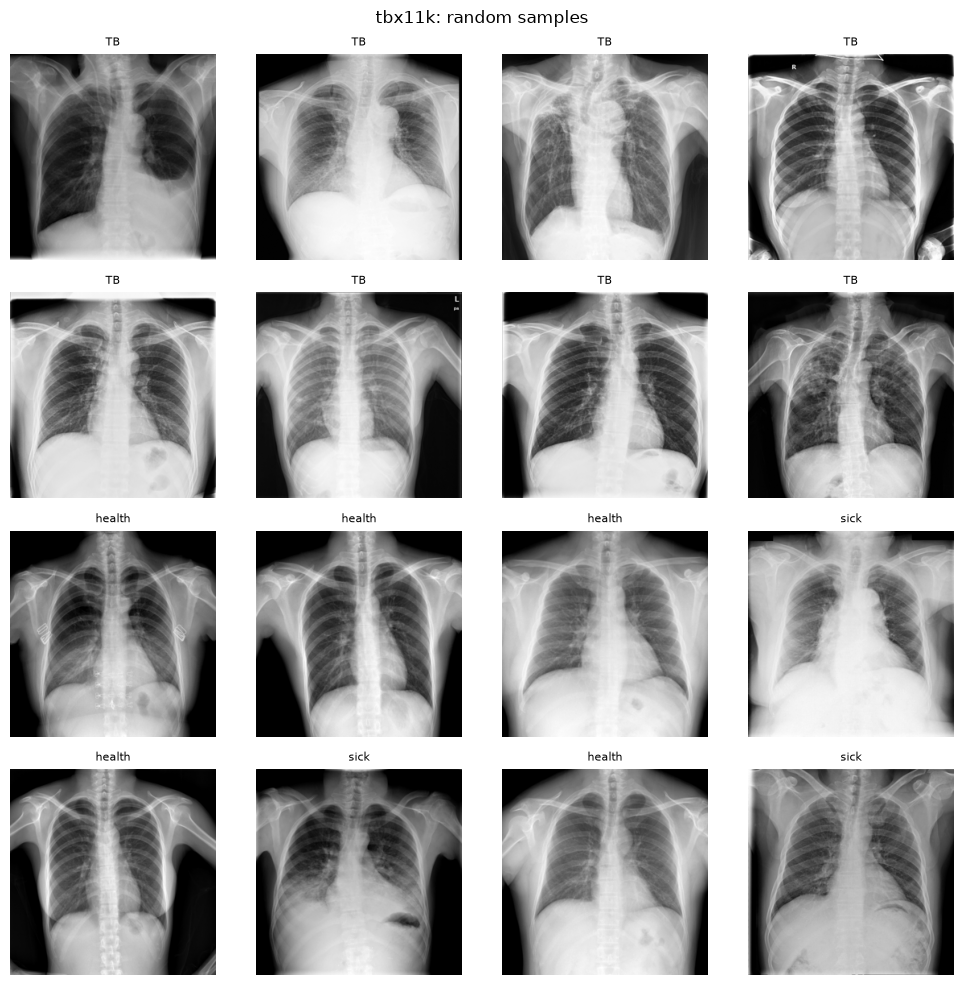

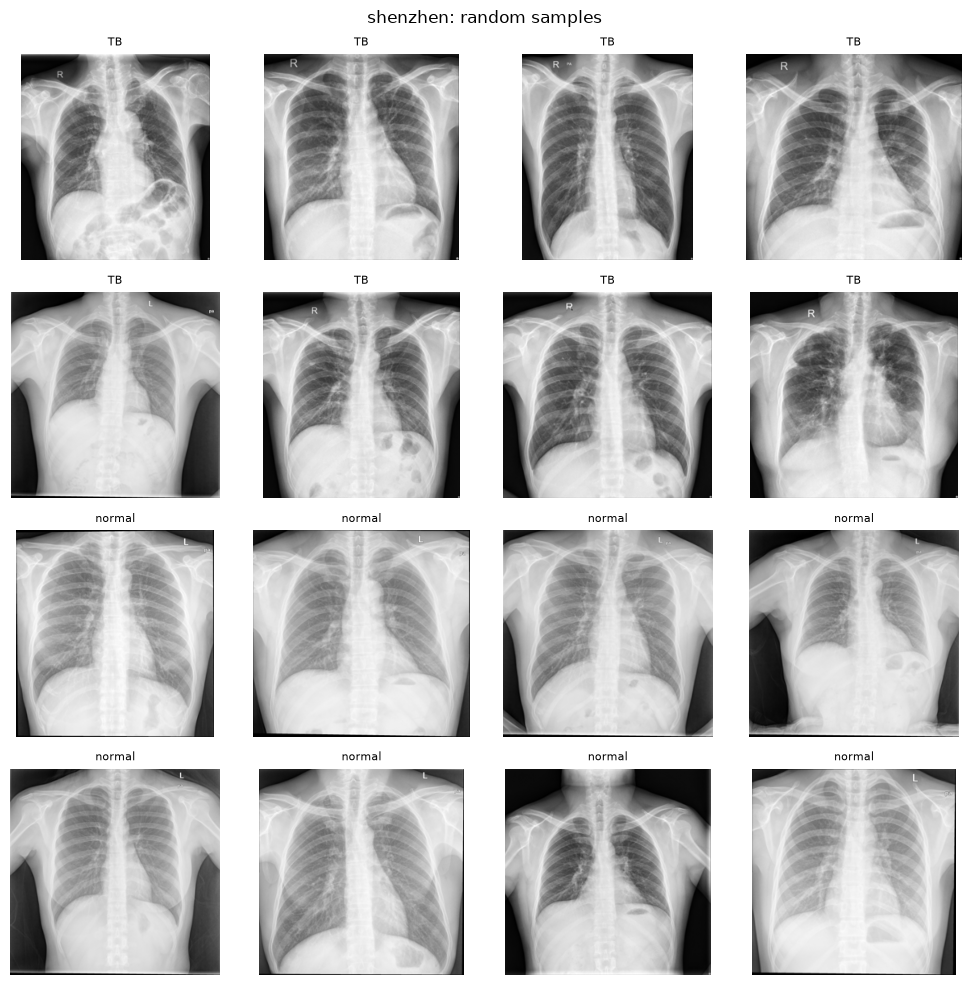

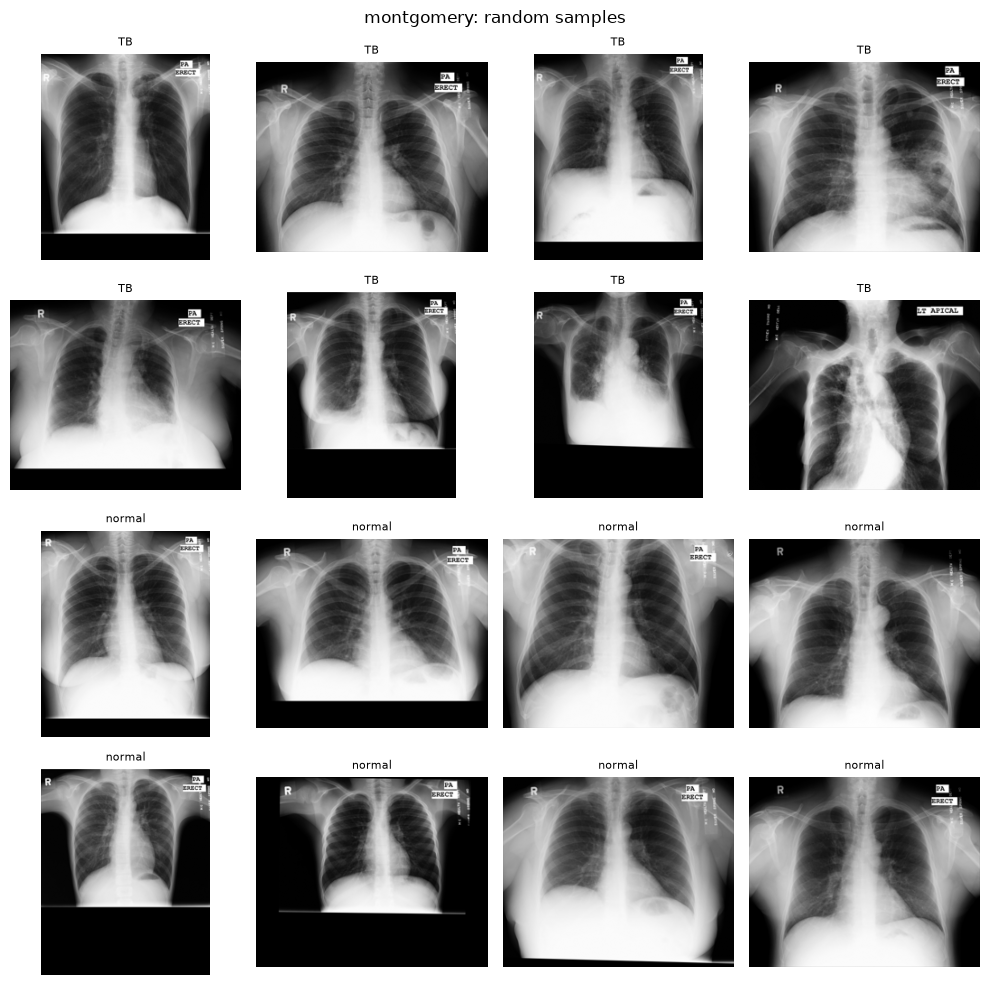

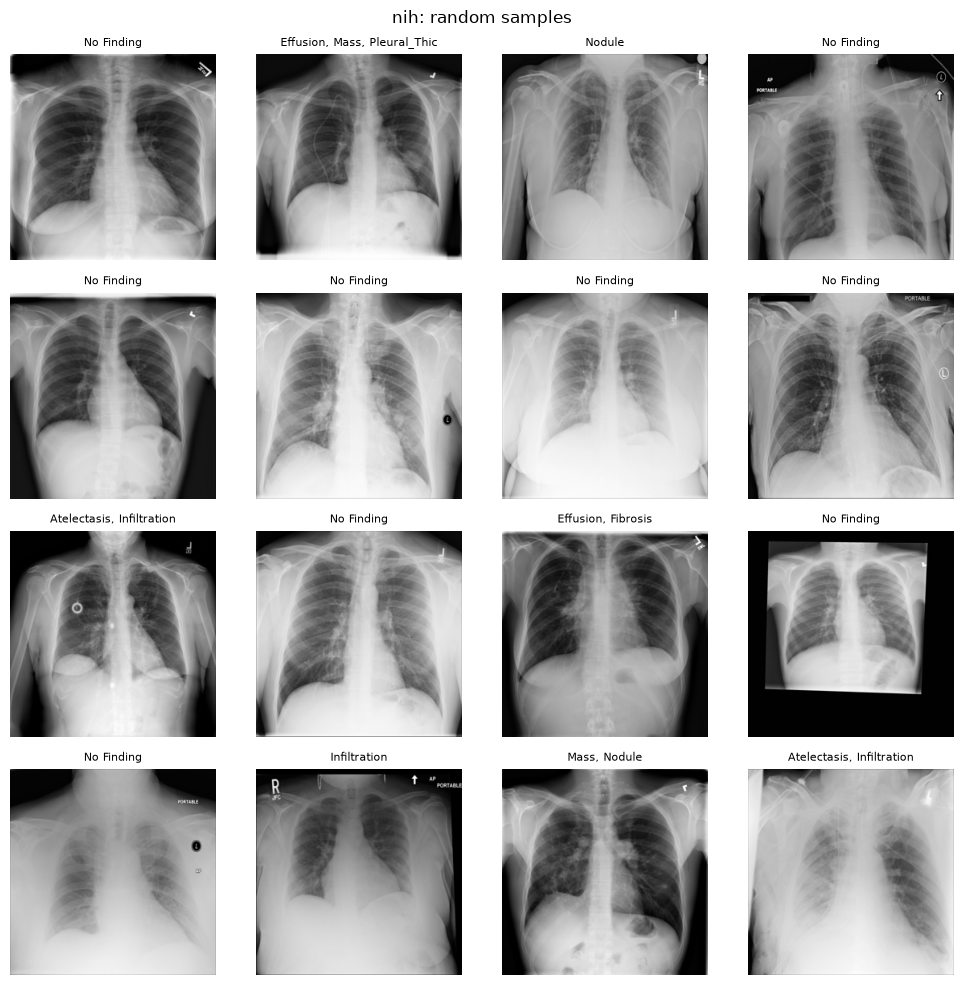

In [ ]:
eda.sample_grids(dfs, ROOT, LOCAL, seed=42)

---
# Part 2 · Checks that set preprocessing

In [ ]:
import ml.eda.checks as checks

SAMPLE = 200  # images per source/mode for sampled checks
extra = {}

## 11. Image modes and real grayscale

Census of every image's mode (header only, fast), then: are RGB / palette / RGBA images really gray?

modes nih: 100%|██████████| 112093/112093 [01:31<00:00, 1227.84it/s]


mode,L,P,RGB,RGBA
source,,,,
montgomery,138,0,0,0
nih,111574,0,0,519
shenzhen,0,635,27,0
tbx11k,0,0,8248,0


channels tbx11k/RGB: 100%|██████████| 200/200 [00:01<00:00, 100.58it/s]


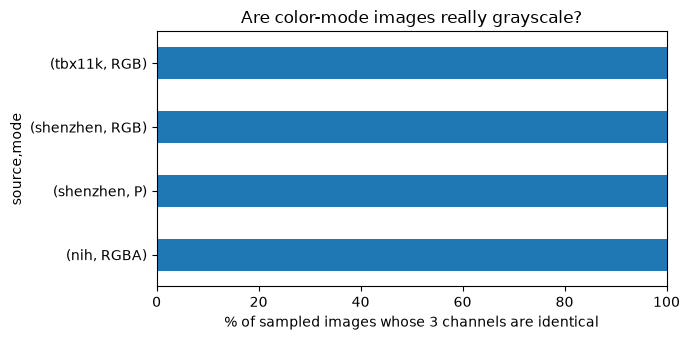

,source,mode,sampled,gray_percent,max_channel_diff,min_alpha
0,nih,RGBA,200,100.0,0,255
1,shenzhen,P,200,100.0,0,255
2,shenzhen,RGB,27,100.0,0,255
3,tbx11k,RGB,200,100.0,0,255


In [ ]:
census = checks.mode_census(dfs, ROOT)
display(census.groupby(["source", "mode"]).size().unstack(fill_value=0))

channels = checks.channel_check(census, ROOT, OUT, n=SAMPLE)
extra["color_modes"] = channels.groupby(["source", "mode"]).agg(
    sampled=("is_gray", "size"), gray_percent=("is_gray", lambda s: round(s.mean() * 100, 1)),
    max_channel_diff=("max_channel_diff", "max"), min_alpha=("alpha_min", "min")).reset_index()
extra["color_modes"]

## 12. Inverted images

Palette check (P images) plus a brightness heuristic: inverted X-rays have bright corners.

inversion tbx11k/RGB: 100%|██████████| 200/200 [00:01<00:00, 159.07it/s]


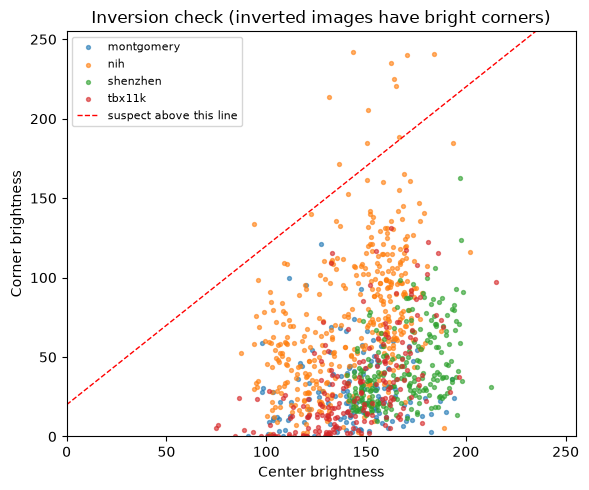

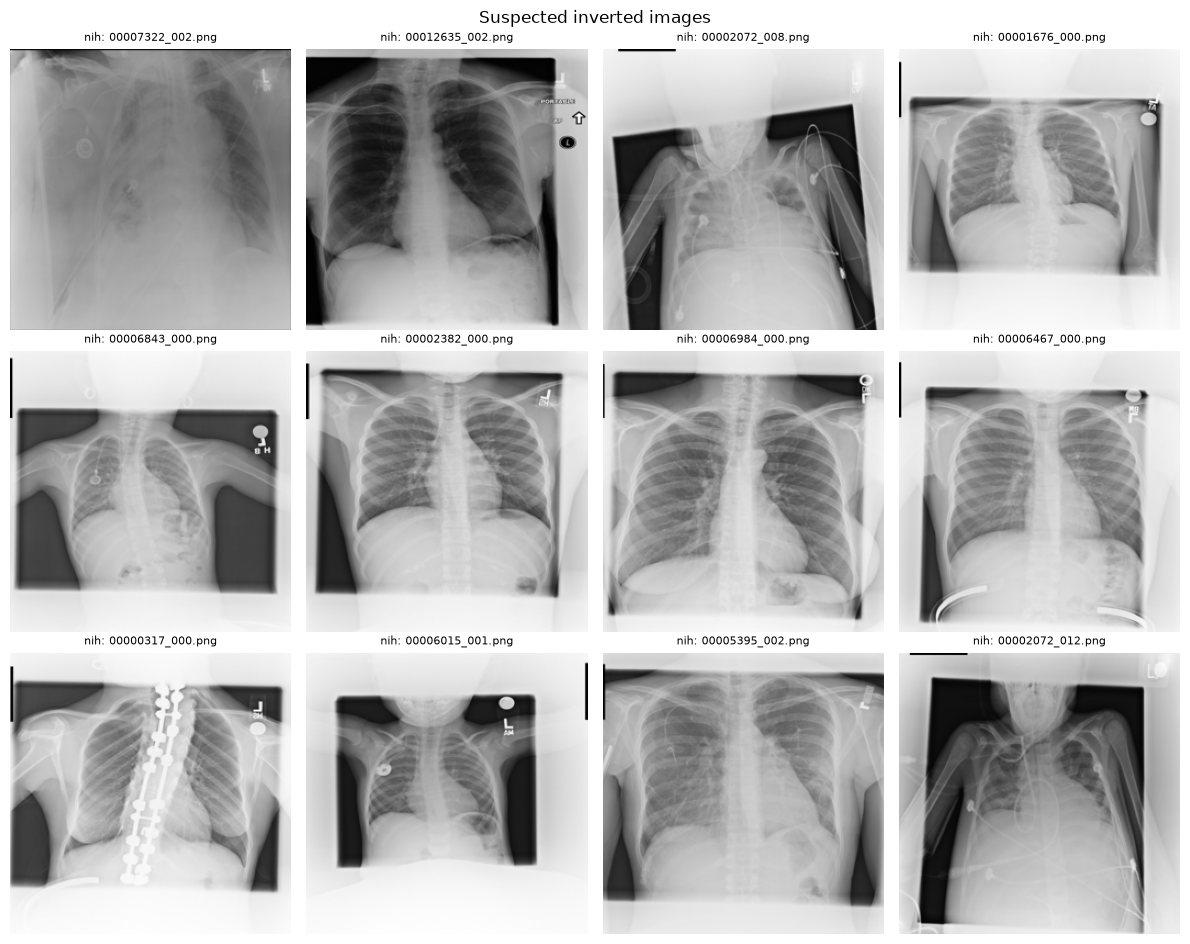

,source,sampled,suspect_inverted,palette_inverted
0,montgomery,138,0,0
1,nih,400,12,0
2,shenzhen,227,0,108
3,tbx11k,200,0,0


In [ ]:
inv = checks.inversion_check(census, ROOT, OUT, LOCAL, n=SAMPLE)
extra["inversion"] = inv.groupby("source").agg(
    sampled=("suspect_inverted", "size"), suspect_inverted=("suspect_inverted", "sum"),
    palette_inverted=("palette_inverted", lambda s: int(s.fillna(False).sum()))).reset_index()
extra["inversion"]

## 13. Borders and aspect ratio

borders: 100%|██████████| 738/738 [00:38<00:00, 19.09it/s] 


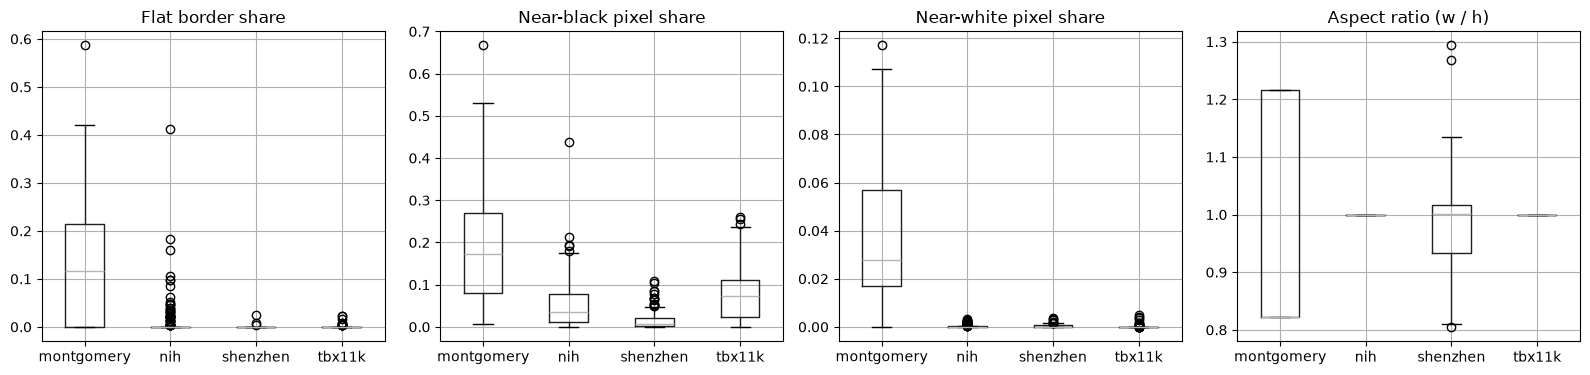

,border_frac,black_frac,white_frac,aspect
source,,,,
montgomery,0.117,0.174,0.028,0.822
nih,0.000,0.035,0.000,1.000
shenzhen,0.000,0.007,0.000,1.002
tbx11k,0.000,0.073,0.000,1.000


In [ ]:
borders = checks.border_check(dfs, ROOT, OUT, n=SAMPLE)
extra["borders"] = borders.groupby("source")[["border_frac", "black_frac", "white_frac", "aspect"]].median().round(3)
extra["borders"]

## 14. Lesion size vs training resolution

NIH boxes rescaled to the model input. Tiny boxes at 224 px argue for 320 px.

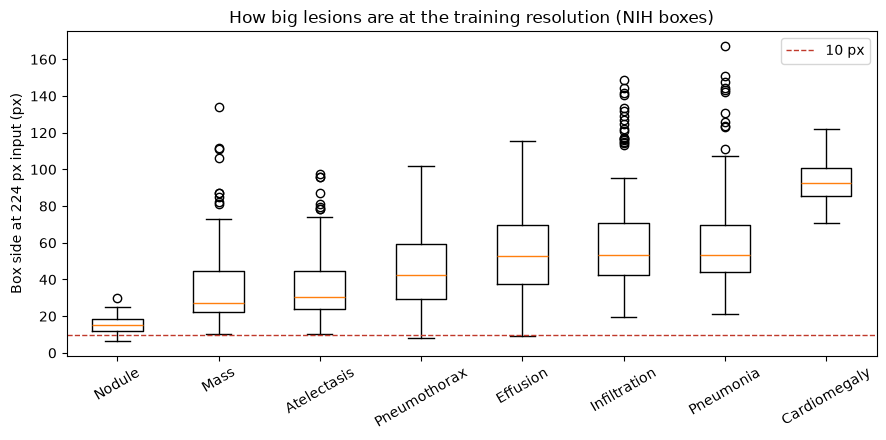

,boxes,median_side_1024,median_side_224,median_side_320,min_side_224
finding,,,,,
Nodule,79,69.3,15.2,21.7,6.4
Mass,85,124.4,27.2,38.9,10.4
Atelectasis,180,140.2,30.7,43.8,10.2
Pneumothorax,98,193.8,42.4,60.6,8.1
Effusion,153,241.7,52.9,75.5,9.1
Infiltration,123,243.7,53.3,76.1,19.8
Pneumonia,120,244.9,53.6,76.5,21.1
Cardiomegaly,146,423.3,92.6,132.3,70.6


In [ ]:
extra["bbox_sizes"] = checks.bbox_sizes(ROOT, OUT)
extra["bbox_sizes"]

## 15. Duplicate pairs for review (local only)

Near-identical pairs that were removed, plus cross-split pairs that were kept.

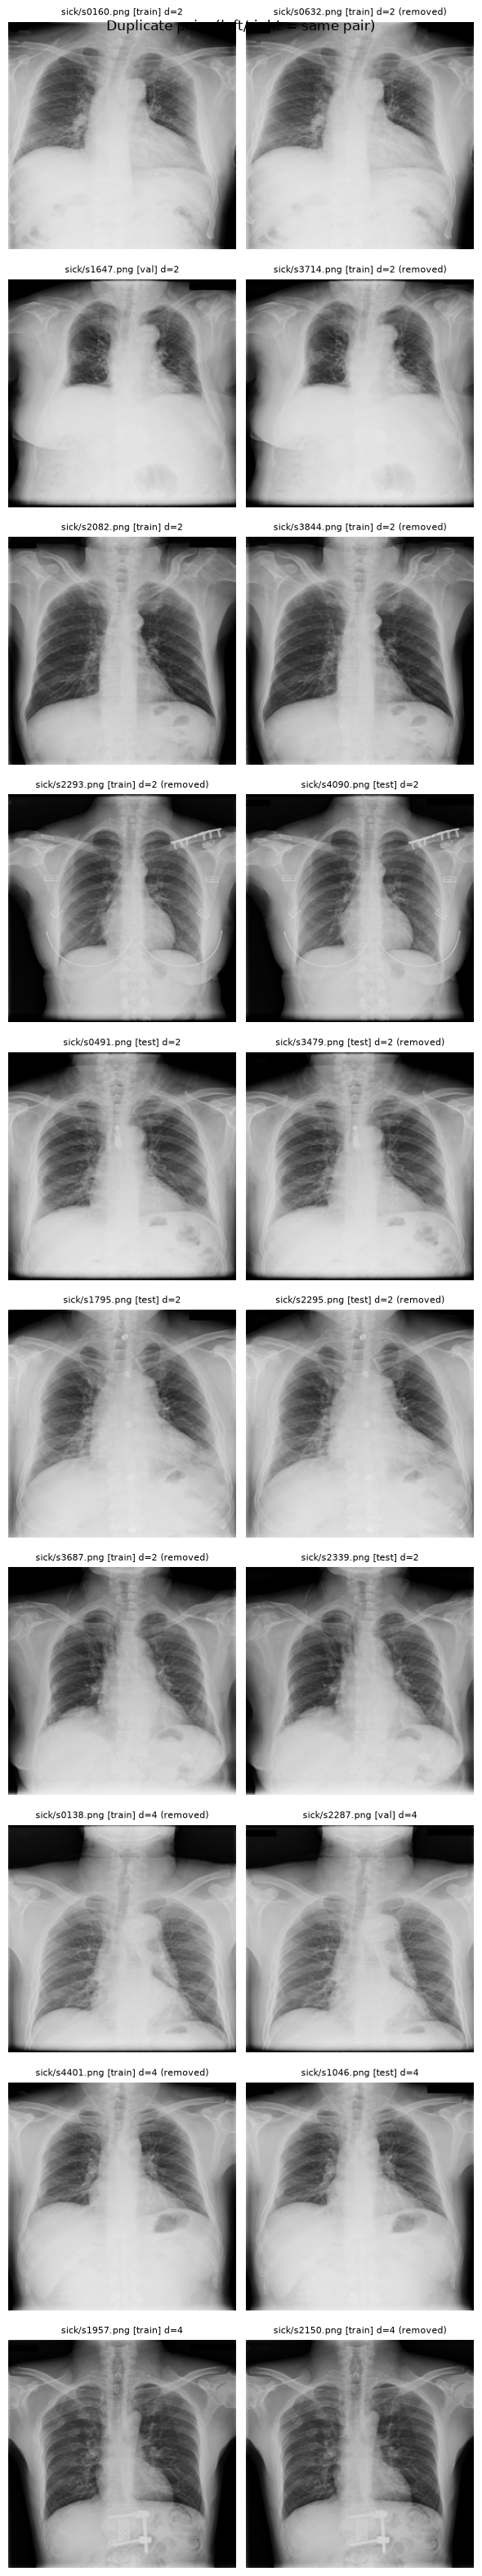

,image_a,split_a,image_b,split_b,phash_distance,exact_match,action
8,tbx11k:sick/s0160.png,train,tbx11k:sick/s0632.png,train,2,False,removed tbx11k:sick/s0632.png from train
68,tbx11k:sick/s1647.png,val,tbx11k:sick/s3714.png,train,2,False,removed tbx11k:sick/s3714.png from train
85,tbx11k:sick/s2082.png,train,tbx11k:sick/s3844.png,train,2,False,removed tbx11k:sick/s3844.png from train
94,tbx11k:sick/s2293.png,train,tbx11k:sick/s4090.png,test,2,False,removed tbx11k:sick/s2293.png from train
146,tbx11k:sick/s0491.png,test,tbx11k:sick/s3479.png,test,2,False,removed tbx11k:sick/s3479.png from test
148,tbx11k:sick/s1795.png,test,tbx11k:sick/s2295.png,test,2,False,removed tbx11k:sick/s2295.png from test
125,tbx11k:sick/s3687.png,train,tbx11k:sick/s2339.png,test,2,False,removed tbx11k:sick/s3687.png from train
7,tbx11k:sick/s0138.png,train,tbx11k:sick/s2287.png,val,4,False,removed tbx11k:sick/s0138.png from train
137,tbx11k:sick/s4401.png,train,tbx11k:sick/s1046.png,test,4,False,removed tbx11k:sick/s4401.png from train
80,tbx11k:sick/s1957.png,train,tbx11k:sick/s2150.png,train,4,False,removed tbx11k:sick/s2150.png from train


In [ ]:
checks.duplicate_review(dfs, ROOT, LOCAL)

---
# Part 3 · Checks for the report

## 16. Prevalence by age, sex and view (NIH train)

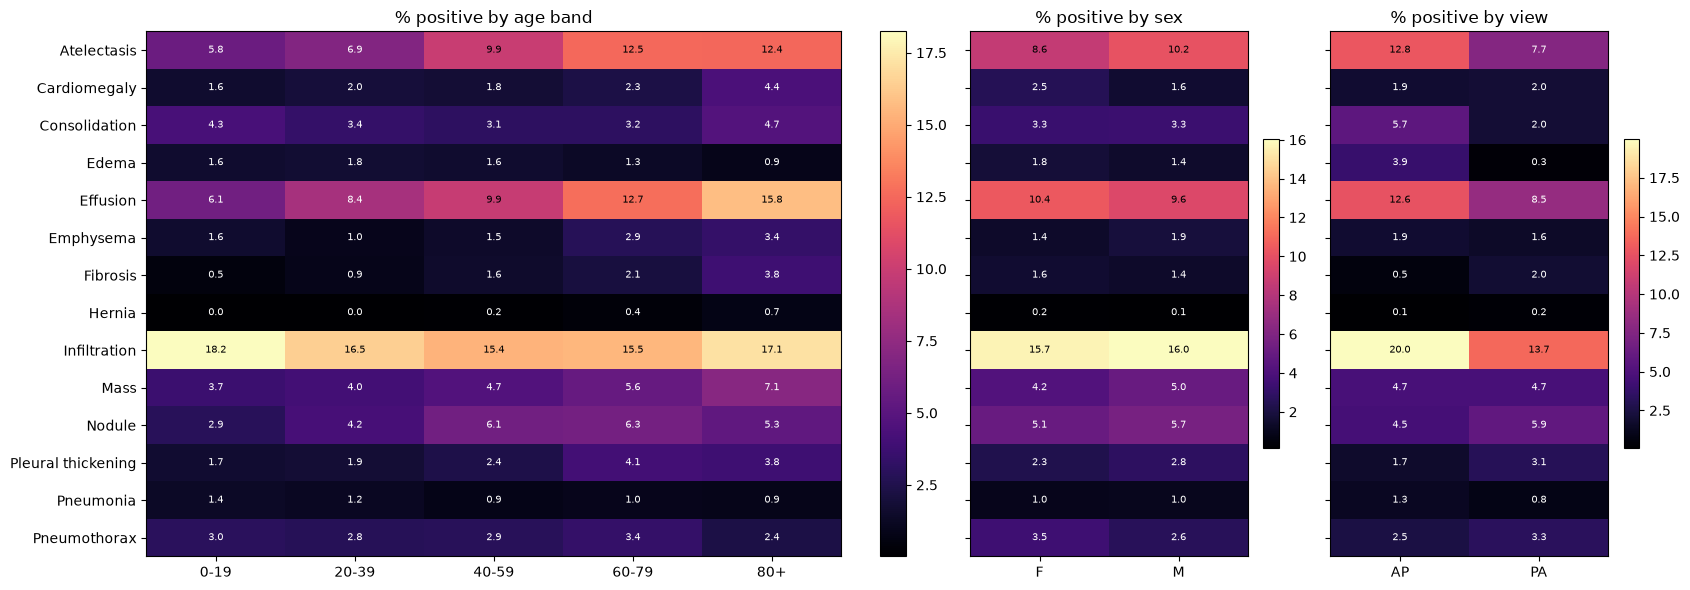

age_band,0-19,20-39,40-59,60-79,80+
Atelectasis,5.80,6.91,9.92,12.48,12.41
Cardiomegaly,1.59,1.98,1.81,2.30,4.43
Consolidation,4.25,3.42,3.12,3.15,4.73
Edema,1.63,1.77,1.62,1.33,0.89
Effusion,6.09,8.43,9.90,12.72,15.81
Emphysema,1.59,0.99,1.46,2.85,3.40
Fibrosis,0.45,0.94,1.57,2.09,3.84
Hernia,0.02,0.02,0.16,0.36,0.74
Infiltration,18.24,16.46,15.35,15.52,17.13
Mass,3.71,4.04,4.65,5.63,7.09


sex,F,M
Atelectasis,8.59,10.16
Cardiomegaly,2.51,1.56
Consolidation,3.28,3.30
Edema,1.79,1.44
Effusion,10.43,9.61
Emphysema,1.39,1.90
Fibrosis,1.57,1.39
Hernia,0.22,0.12
Infiltration,15.69,16.02
Mass,4.20,5.05


view,AP,PA
Atelectasis,12.84,7.67
Cardiomegaly,1.87,2.03
Consolidation,5.69,2.00
Edema,3.92,0.34
Effusion,12.65,8.53
Emphysema,1.90,1.56
Fibrosis,0.53,1.97
Hernia,0.06,0.22
Infiltration,19.97,13.68
Mass,4.70,4.66


In [ ]:
groups = checks.prevalence_by_group(nih_train, OUT)
display(groups["age_band"])
display(groups["sex"])
groups["view"]

## 17. Positivity vs follow-up number

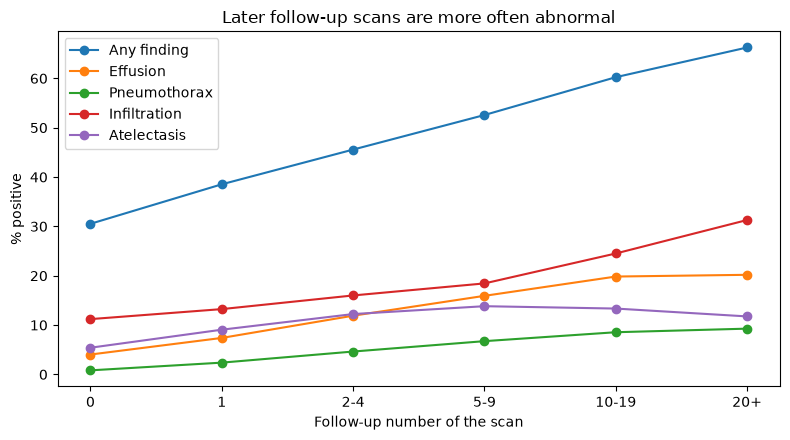

,Any finding,Effusion,Pneumothorax,Infiltration,Atelectasis,images
follow_up_bin,,,,,,
0,30.5,4.0,0.8,11.2,5.4,30803
1,38.5,7.4,2.4,13.2,9.1,13301
2-4,45.6,11.9,4.6,16.0,12.2,22024
5-9,52.6,15.9,6.7,18.4,13.8,17754
10-19,60.2,19.8,8.5,24.5,13.3,14007
20+,66.3,20.2,9.3,31.3,11.8,14204


In [ ]:
extra["followup"] = checks.followup_effect(nih, OUT)
extra["followup"]

## 18. Sharpness and exposure

The 1st / 99th percentiles become starting thresholds for the app's image-quality check.

quality: 100%|██████████| 738/738 [00:41<00:00, 17.85it/s] 


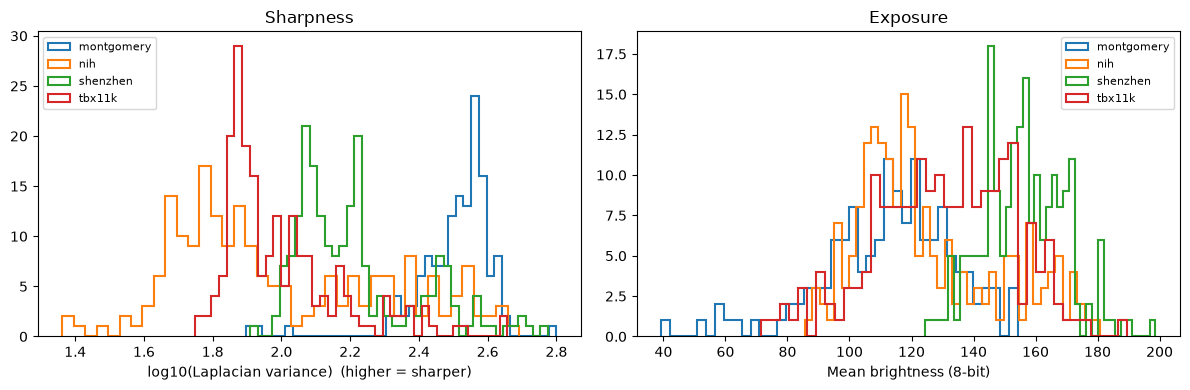

,sharpness,mean,dark_frac,bright_frac
source,,,,
montgomery,338.63,114.89,0.18,0.03
nih,77.64,118.66,0.04,0.00
shenzhen,148.58,155.95,0.01,0.00
tbx11k,85.93,132.14,0.07,0.00


{'min_sharpness_p1': 34.7,
 'mean_brightness_p1': 82.9,
 'mean_brightness_p99': 175.3}

In [ ]:
quality, thresholds = checks.quality_stats(dfs, ROOT, OUT, n=SAMPLE)
display(quality.groupby("source")[["sharpness", "mean", "dark_frac", "bright_frac"]].median().round(2))
extra["quality_thresholds"] = thresholds
thresholds

## 19. External readings that disagree with labels

In [ ]:
extra["reading_mismatches"] = checks.reading_mismatches(dfs, ROOT, LOCAL)
extra["reading_mismatches"]

,image_id,label_tb,reading,age,sex,notes


## Save Part 2–3 summary

In [ ]:
def _jsonable(v):
    return v.reset_index().to_dict("records") if isinstance(v, pd.DataFrame) else v

(OUT / "eda_checks_summary.json").write_text(json.dumps({k: _jsonable(v) for k, v in extra.items()}, indent=2, default=str))
print("saved", OUT / "eda_checks_summary.json")

saved c:\Users\krish.LAPTOP-3EPNQNP7\Downloads\pneumyst-ai\docs\figures\eda\eda_checks_summary.json


---
# Part 4 · Shortcut and leakage checks

In [ ]:
import ml.eda.probes as probes

probe = {}

## 20. TBX11K shortcut probe

A linear model sees only global stats (brightness, contrast, sharpness, borders, 16-bin histogram), never lung structure. Columns: the same probe after each normalization.

AUROC ≈ 0.5: no trivial shortcut · 0.6–0.75: some acquisition difference · ≥ 0.75: classes differ in how they were captured (risk).

TBX11K classes:   0%|          | 0/2400 [00:00<?, ?it/s]

TBX11K classes: 100%|██████████| 2400/2400 [00:38<00:00, 62.31it/s]


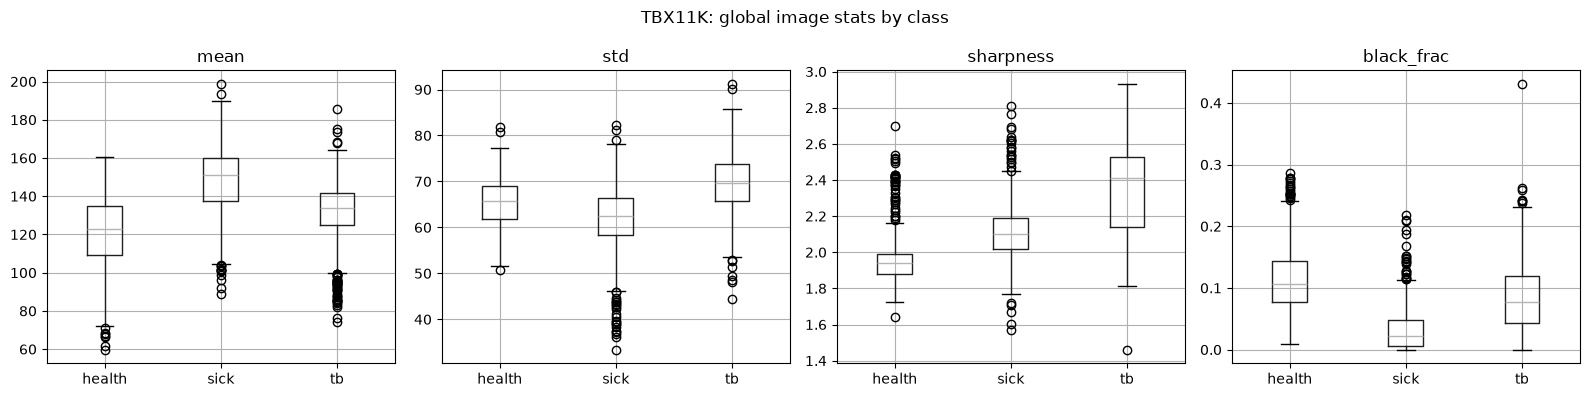

,mean,std,p1,p99,sharpness,border_frac,black_frac,white_frac
group,,,,,,,,
health,123.031,65.652,0.0,226.0,1.939,0.0,0.107,0.0
sick,150.940,62.399,3.0,228.0,2.103,0.0,0.023,0.0
tb,134.002,69.676,0.0,232.0,2.413,0.0,0.077,0.0


method,none,percentile,clahe
comparison,,,
health vs sick,0.985,0.984,0.992
health vs tb,0.976,0.963,0.977
sick vs tb,0.938,0.941,0.963


In [ ]:
stats20, auc20 = probes.tbx_class_probe(dfs["tbx11k"], ROOT, OUT, n_per_class=800,
                                        methods=tuple(probes.NORMALIZATIONS))
display(stats20)
probe["tbx11k_class_probe"] = auc20
auc20

## 21–22. Hospital fingerprint and normalization

Normal images only, so no disease signal. A lower AUROC after normalization means less domain shift.

normals x 3 methods:   0%|          | 0/806 [00:00<?, ?it/s]

normals x 3 methods: 100%|██████████| 806/806 [00:40<00:00, 20.01it/s]


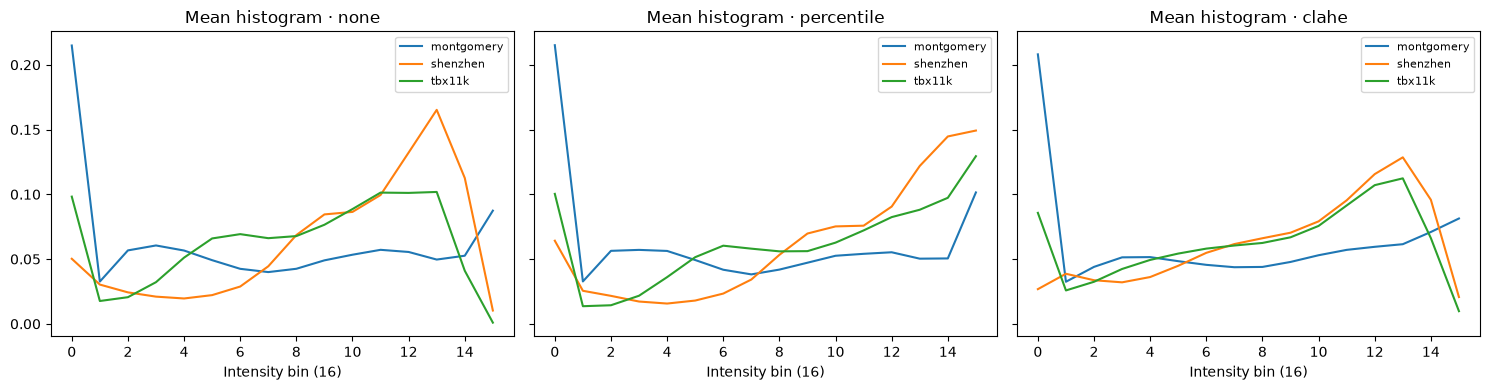

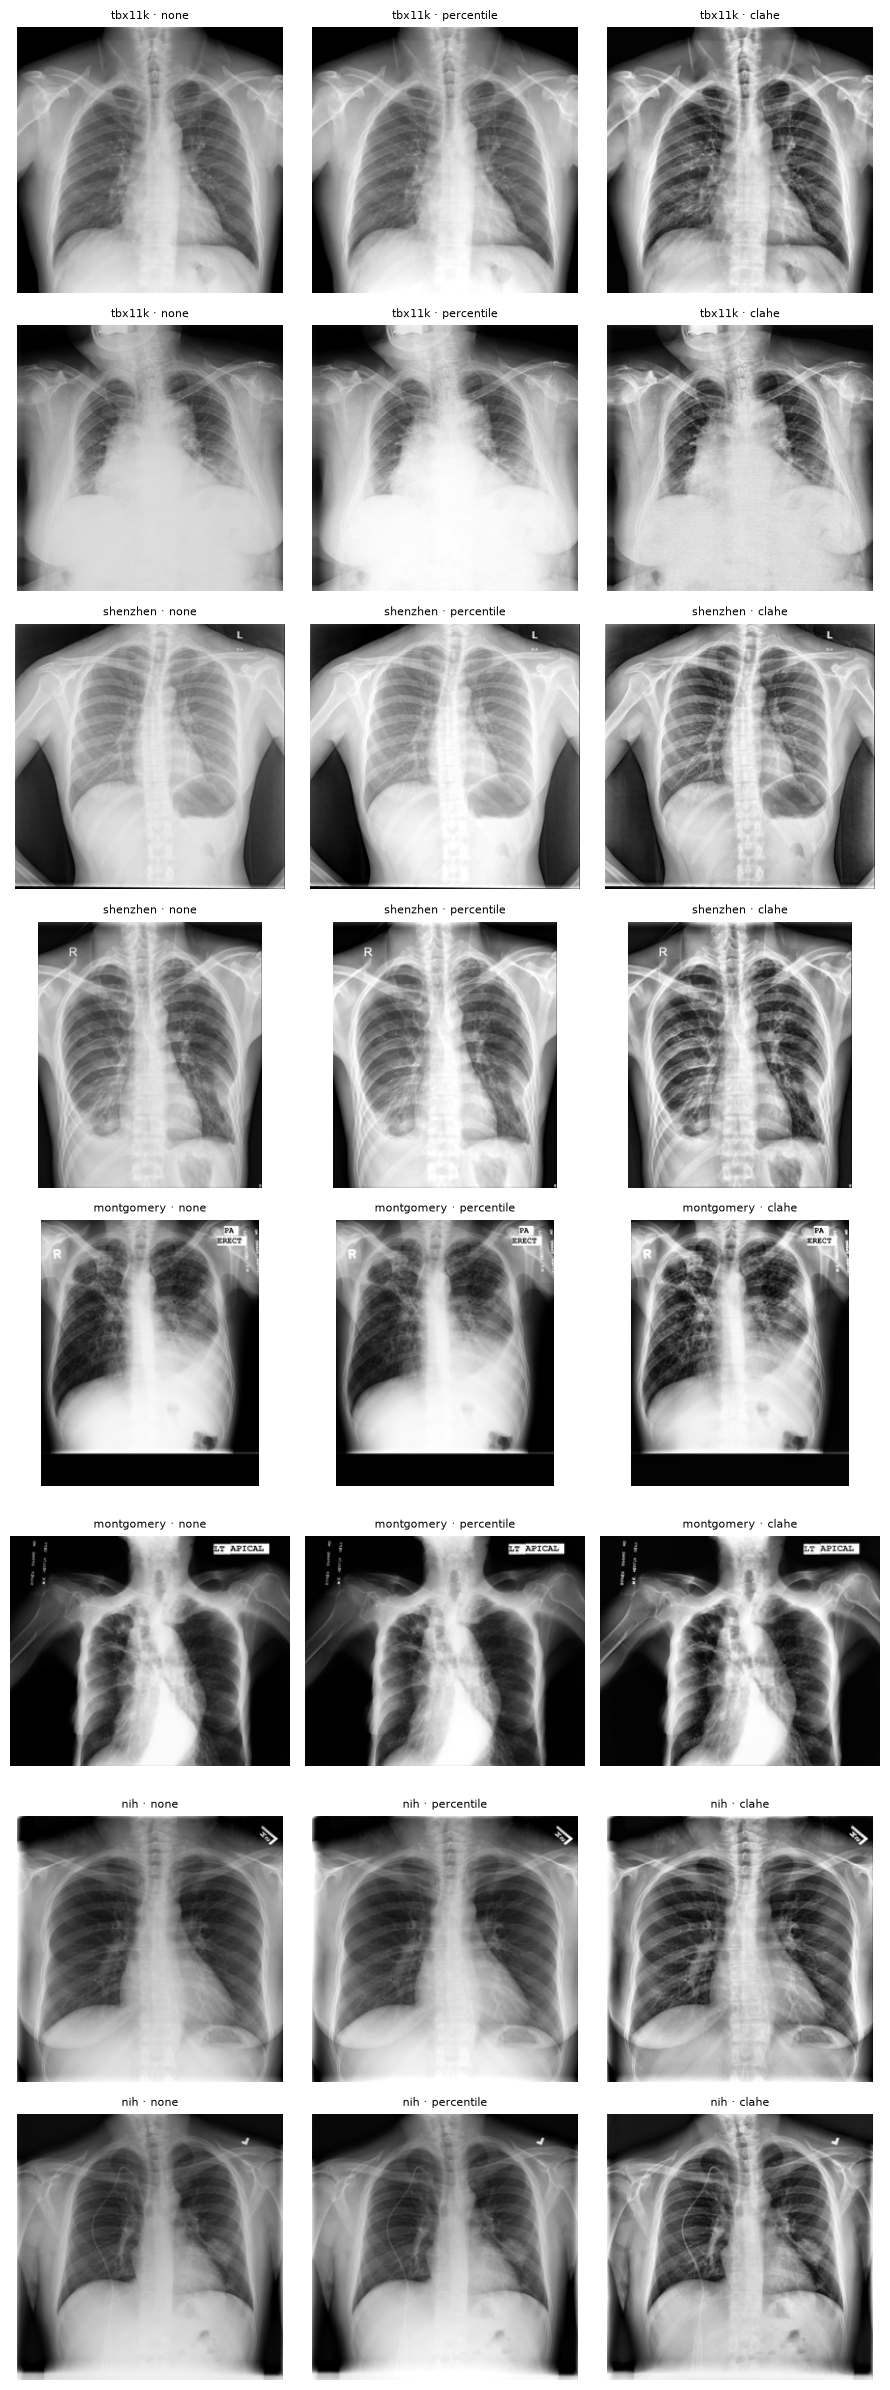

method,none,percentile,clahe
comparison,,,
montgomery vs shenzhen,1.000,1.000,1.000
montgomery vs tbx11k,1.000,1.000,1.000
shenzhen vs tbx11k,0.994,0.989,0.996


In [ ]:
fp_table, _ = probes.origin_probe(dfs, ROOT, OUT, n=400)
probes.normalization_preview(dfs, ROOT, LOCAL)
probe["origin_probe"] = fp_table
fp_table

## 23. NIH duplicate search (all 112k)

Hashes are cached to `processed/manifests/nih_hashes.csv` and reused by preprocessing. First run takes ~10–20 min.

If it hangs on Windows, set `workers=1`.

In [ ]:
nih_hash = probes.nih_hashes(nih, ROOT, ROOT / "processed" / "manifests" / "nih_hashes.csv", workers=4)
dup_report, dup_summary = probes.nih_duplicates(nih, nih_hash, ROOT / "processed" / "manifests" / "nih_duplicates.csv")
probes.duplicate_grid(dup_report, nih, ROOT, LOCAL / "nih_leak_pairs.png")
probe["nih_duplicates"] = dup_summary
display(dup_summary)
dup_report[dup_report["kind"].str.startswith("LEAK")].head(20)

hashing NIH: 100%|██████████| 112093/112093 [06:39<00:00, 280.85it/s]


{'hashed': 112093,
 'unreadable': 0,
 'pairs': 0,
 'oversized_buckets_skipped': 0,
 'by_kind': {}}

,image_a,patient_a,split_a,image_b,patient_b,split_b,phash_distance,exact_match,kind


## Save Part 4 summary

In [ ]:
def _jsonable(v):
    return v.reset_index().to_dict("records") if isinstance(v, pd.DataFrame) else v

(OUT / "eda_probes_summary.json").write_text(json.dumps({k: _jsonable(v) for k, v in probe.items()}, indent=2, default=str))
print("saved", OUT / "eda_probes_summary.json")

saved c:\Users\krish.LAPTOP-3EPNQNP7\Downloads\pneumyst-ai\docs\figures\eda\eda_probes_summary.json
